In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path

# folder dataset
DATASET_DIR = Path('/content/drive/MyDrive/Daun Cabai')

# Folder keluaran eksperimen
OUTPUT_DIR = Path('/content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {DATASET_DIR}\n"
        "Periksa kembali nama dan lokasi folder di Google Drive."
    )

print("Dataset ditemukan:", DATASET_DIR)
print("Hasil akan disimpan di:", OUTPUT_DIR)

Mounted at /content/drive
Dataset ditemukan: /content/drive/MyDrive/Daun Cabai
Hasil akan disimpan di: /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0


In [ ]:
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_recall_fscore_support
)
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: []


In [ ]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

records = []
corrupt_files = []

class_dirs = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()])

if len(class_dirs) < 2:
    raise ValueError(
        "Dataset harus memiliki minimal 2 folder kelas. "
        "Periksa struktur folder dataset."
    )

for class_dir in class_dirs:
    image_paths = [
        p for p in class_dir.rglob('*')
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for image_path in image_paths:
        try:
            with Image.open(image_path) as img:
                img.verify()
            records.append({
                'filepath': str(image_path),
                'label': class_dir.name
            })
        except Exception:
            corrupt_files.append(str(image_path))

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("Tidak ditemukan gambar yang valid di folder kelas.")

print("Jumlah gambar valid:", len(df))
print("Jumlah gambar rusak/tidak terbaca:", len(corrupt_files))
print("\nJumlah gambar per kelas:")
print(df['label'].value_counts().sort_index())

if corrupt_files:
    print("\nContoh file bermasalah:")
    for p in corrupt_files[:20]:
        print(p)

display(df.head())

Jumlah gambar valid: 738
Jumlah gambar rusak/tidak terbaca: 0

Jumlah gambar per kelas:
label
Daun karat       336
Daun keriting    259
Daun sehat       143
Name: count, dtype: int64


,filepath,label
0,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat
1,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat
2,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat
3,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat
4,/content/drive/MyDrive/Daun Cabai/Daun karat/I...,Daun karat


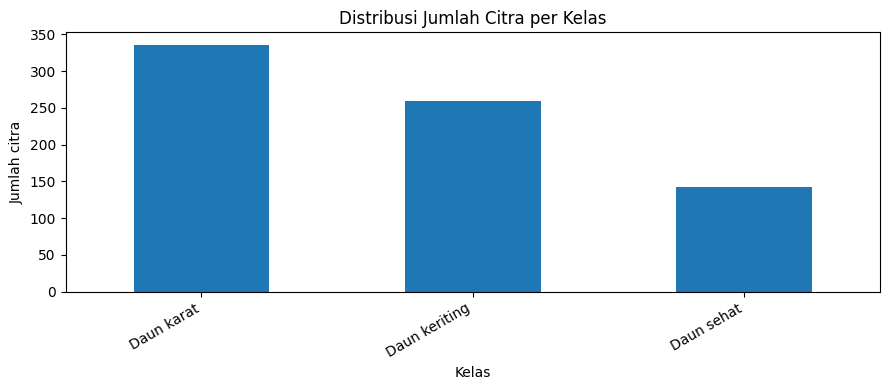

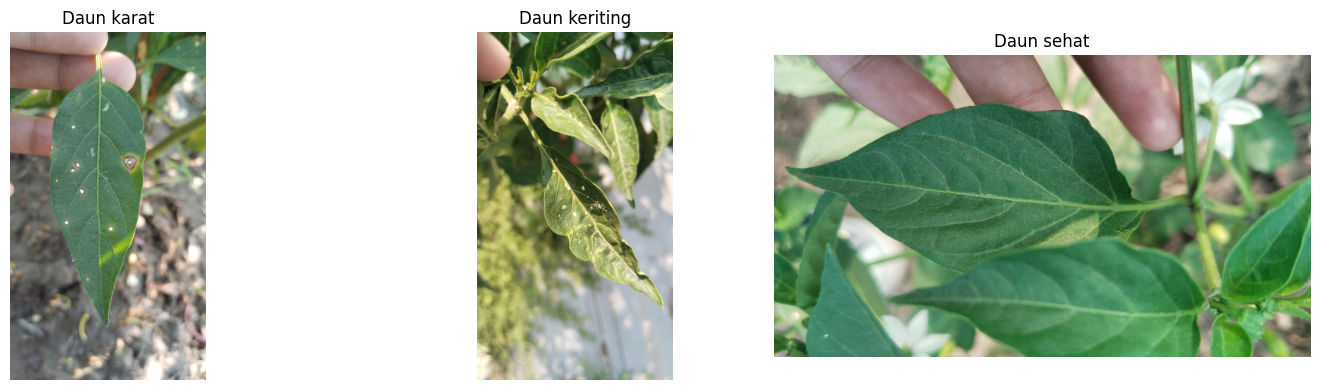

In [ ]:
class_counts = df['label'].value_counts().sort_index()

plt.figure(figsize=(9, 4))
class_counts.plot(kind='bar')
plt.title('Distribusi Jumlah Citra per Kelas')
plt.xlabel('Kelas')
plt.ylabel('Jumlah citra')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

class_names = sorted(df['label'].unique())

fig, axes = plt.subplots(1, len(class_names), figsize=(5 * len(class_names), 4))
if len(class_names) == 1:
    axes = [axes]

for ax, class_name in zip(axes, class_names):
    sample_path = df[df['label'] == class_name].sample(
        1, random_state=SEED
    )['filepath'].iloc[0]
    with Image.open(sample_path) as img:
        ax.imshow(img.convert('RGB'))
    ax.set_title(class_name)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
class_names = sorted(df['label'].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}
index_to_class = {i: name for name, i in class_to_index.items()}

df['label_encoded'] = df['label'].map(class_to_index).astype('int32')

# 70% train, 30% sementara
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df['label_encoded']
)

# 15% validation, 15% test dari keseluruhan dataset
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df['label_encoded']
)

print(f"Training   : {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation : {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Testing    : {len(test_df)} ({len(test_df)/len(df):.1%})")

for split_name, split_df in [
    ('Training', train_df), ('Validation', val_df), ('Testing', test_df)
]:
    print(f"\n{split_name}:")
    print(split_df['label'].value_counts().sort_index())

# Simpan split untuk di Notebook 2
train_df.to_csv(OUTPUT_DIR / 'data_training.csv', index=False)
val_df.to_csv(OUTPUT_DIR / 'data_validation.csv', index=False)
test_df.to_csv(OUTPUT_DIR / 'data_testing.csv', index=False)

with open(OUTPUT_DIR / 'class_mapping.json', 'w') as f:
    json.dump(
        {'class_to_index': class_to_index, 'index_to_class': index_to_class},
        f, indent=2
    )

print("\nSplit dan pemetaan kelas berhasil disimpan.")

Training   : 516 (69.9%)
Validation : 111 (15.0%)
Testing    : 111 (15.0%)

Training:
label
Daun karat       235
Daun keriting    181
Daun sehat       100
Name: count, dtype: int64

Validation:
label
Daun karat       50
Daun keriting    39
Daun sehat       22
Name: count, dtype: int64

Testing:
label
Daun karat       51
Daun keriting    39
Daun sehat       21
Name: count, dtype: int64

Split dan pemetaan kelas berhasil disimpan.


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(class_names)

# Augmentasi hanya diterapkan pada training.
# Jangan menambahkan Rescaling(1./255): EfficientNetB0 Keras
# memiliki preprocessing/rescaling internal dan menerima piksel 0–255.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name='data_augmentation')

def load_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image_bytes, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

def make_dataset(dataframe, training=False):
    paths = dataframe['filepath'].astype(str).values
    labels = dataframe['label_encoded'].astype('int32').values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.map(
            lambda x, y: (data_augmentation(x, training=True), y),
            num_parallel_calls=AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

print("Pipeline train, validation, dan test siap.")

Pipeline train, validation, dan test siap.


Bentuk batch gambar: (32, 224, 224, 3)
Bentuk batch label: (32,)
Rentang nilai piksel: 0.0 sampai 255.0


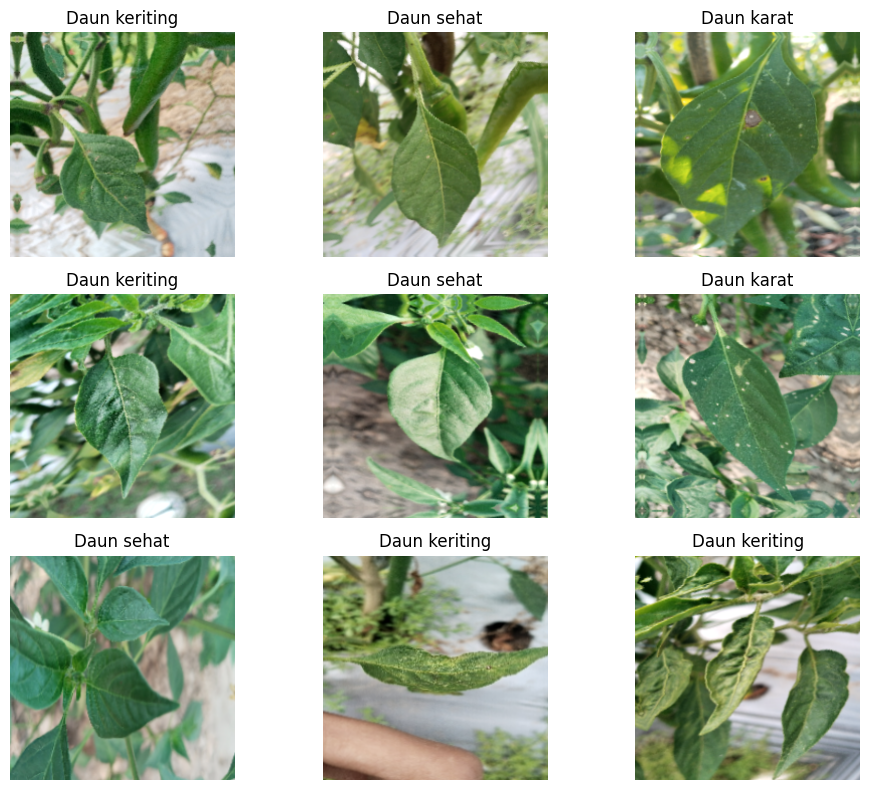

In [ ]:
images, labels = next(iter(train_ds))

print("Bentuk batch gambar:", images.shape)
print("Bentuk batch label:", labels.shape)
print("Rentang nilai piksel:", float(tf.reduce_min(images)), "sampai", float(tf.reduce_max(images)))

plt.figure(figsize=(10, 8))
for i in range(min(9, images.shape[0])):
    plt.subplot(3, 3, i + 1)
    plt.imshow(tf.cast(tf.clip_by_value(images[i], 0, 255), tf.uint8))
    plt.title(index_to_class[int(labels[i].numpy())])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras import layers, Model

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image')
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
x = layers.Dropout(0.30, name='dropout_1')(x)
x = layers.Dense(256, activation='relu', name='dense_256')(x)
x = layers.Dropout(0.30, name='dropout_2')(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

model = Model(inputs, outputs, name='EfficientNetB0_Baseline')
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,278 (16.70 MB)

 Trainable params: 328,707 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model berhasil dikompilasi.")

Model berhasil dikompilasi.


In [ ]:
checkpoint_path = OUTPUT_DIR / 'efficientnet_b0_best.keras'

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        mode='min',
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        mode='min',
        verbose=1
    )
]

EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5504 - loss: 0.9279
Epoch 1: val_loss improved from None to 0.61616, saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/efficientnet_b0_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/efficientnet_b0_best.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 110s 6s/step - accuracy: 0.6628 - loss: 0.7578 - val_accuracy: 0.6757 - val_loss: 0.6162 - learning_rate: 0.0010
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8128 - loss: 0.4991
Epoch 2: val_loss improved from 0.61616 to 0.59817, saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/efficientnet_b0_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0/efficientnet_b0_best.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 93s 5s/step - accuracy: 0.7984 - loss: 0.4884 - val_accuracy: 0.7387 - val_loss: 0.5982 - learning_rate: 0.0010


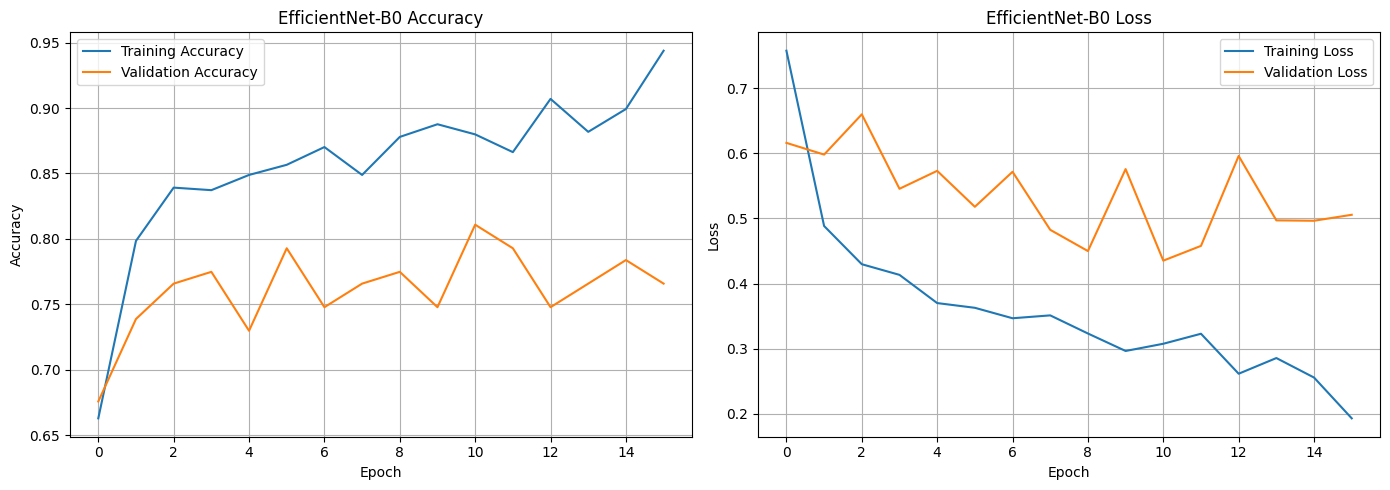

Epoch terbaik berdasarkan validation loss: 11
Validation loss terbaik: 0.4351648986339569


In [ ]:
history_df = pd.DataFrame(history.history)
history_df.to_csv(OUTPUT_DIR / 'history_efficientnet_b0.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_df['accuracy'], label='Training Accuracy')
axes[0].plot(history_df['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('EfficientNet-B0 Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_df['loss'], label='Training Loss')
axes[1].plot(history_df['val_loss'], label='Validation Loss')
axes[1].set_title('EfficientNet-B0 Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Epoch terbaik berdasarkan validation loss:", int(history_df['val_loss'].idxmin()) + 1)
print("Validation loss terbaik:", float(history_df['val_loss'].min()))

4/4 ━━━━━━━━━━━━━━━━━━━━ 35s 5s/step - accuracy: 0.8288 - loss: 0.3902
Test Loss     : 0.3902
Test Accuracy : 0.8288 (82.88%)
4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step

Classification Report:
               precision    recall  f1-score   support

   Daun karat     0.8276    0.9412    0.8807        51
Daun keriting     0.9167    0.8462    0.8800        39
   Daun sehat     0.6471    0.5238    0.5789        21

     accuracy                         0.8288       111
    macro avg     0.7971    0.7704    0.7799       111
 weighted avg     0.8247    0.8288    0.8234       111



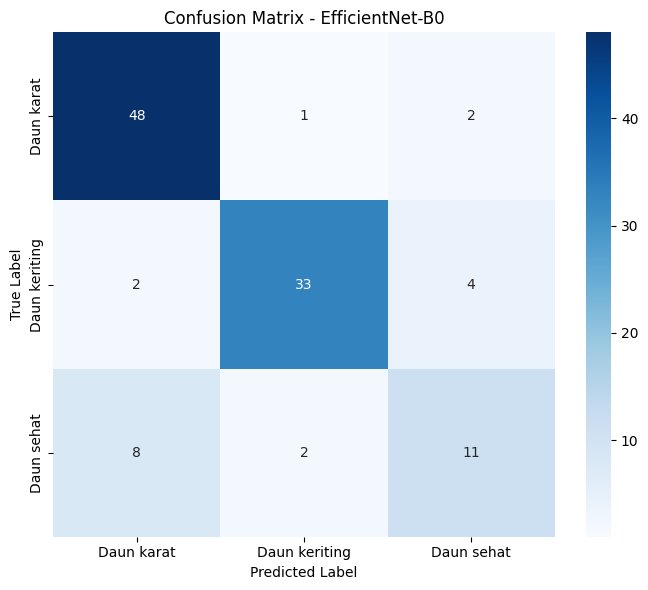


Metrik pengujian disimpan.
{'model': 'EfficientNet-B0', 'test_loss': 0.3901679217815399, 'accuracy': 0.8288288116455078, 'precision_weighted': 0.8247309175301061, 'recall_weighted': 0.8288288288288288, 'f1_weighted': 0.8233813146802041}


In [ ]:
# Muat checkpoint terbaik, bukan sekadar bobot epoch terakhir
best_model = tf.keras.models.load_model(checkpoint_path)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - EfficientNet-B0')
plt.tight_layout()
plt.show()

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average='weighted', zero_division=0
)

metrics_result = {
    'model': 'EfficientNet-B0',
    'test_loss': float(test_loss),
    'accuracy': float(test_accuracy),
    'precision_weighted': float(precision),
    'recall_weighted': float(recall),
    'f1_weighted': float(f1)
}

pd.DataFrame([metrics_result]).to_csv(
    OUTPUT_DIR / 'metrics_efficientnet_b0.csv',
    index=False
)

pd.DataFrame({
    'filepath': test_df['filepath'].values,
    'actual_label': [index_to_class[int(i)] for i in y_true],
    'predicted_label': [index_to_class[int(i)] for i in y_pred]
}).to_csv(OUTPUT_DIR / 'predictions_efficientnet_b0.csv', index=False)

print("\nMetrik pengujian disimpan.")
print(metrics_result)

In [ ]:
# Simpan model final terbaik
best_model.save(OUTPUT_DIR / 'efficientnet_b0_best.keras')

experiment_info = {
    'model': 'EfficientNetB0',
    'image_size': IMG_SIZE,
    'batch_size': BATCH_SIZE,
    'max_epochs': EPOCHS,
    'seed': SEED,
    'class_names': class_names,
    'split_ratio': {'train': 0.70, 'validation': 0.15, 'test': 0.15},
    'pretrained_weights': 'ImageNet',
    'backbone_frozen': True,
    'augmentation_training_only': True
}

with open(OUTPUT_DIR / 'experiment_info.json', 'w') as f:
    json.dump(experiment_info, f, indent=2)

print("Selesai. Seluruh hasil tersimpan di:", OUTPUT_DIR)

Selesai. Seluruh hasil tersimpan di: /content/drive/MyDrive/Hasil_Penelitian_Cabai/EfficientNetB0
